Lab Assignment -6 

Task 1: Data Acquisition and Exploration 

Resuming download from 721420288 bytes (1741945147 bytes left)...
Resuming download to C:\Users\User\.cache\kagglehub\datasets\paultimothymooney\chest-xray-pneumonia\2.archive (721420288/2463365435) bytes left.


100%|██████████| 2.29G/2.29G [01:51<00:00, 15.7MB/s]

Extracting files...


Downloaded dataset location: C:\Users\User\.cache\kagglehub\datasets\paultimothymooney\chest-xray-pneumonia\versions\2
Dataset folder used: C:\Users\User\.cache\kagglehub\datasets\paultimothymooney\chest-xray-pneumonia\versions\2\chest_xray

First five records:
                                                                                                                           filepath  label original_split
C:\Users\User\.cache\kagglehub\datasets\paultimothymooney\chest-xray-pneumonia\versions\2\chest_xray\train\NORMAL\IM-0115-0001.jpeg NORMAL          train
C:\Users\User\.cache\kagglehub\datasets\paultimothymooney\chest-xray-pneumonia\versions\2\chest_xray\train\NORMAL\IM-0117-0001.jpeg NORMAL          train
C:\Users\User\.cache\kagglehub\datasets\paultimothymooney\chest-xray-pneumonia\versions\2\chest_xray\train\NORMAL\IM-0119-0001.jpeg NORMAL          train
C:\Users\User\.cache\kagglehub\datasets\paultimothymooney\chest-xray-pneumonia\versions\2\chest_xray\train\NORMAL\IM-0122-

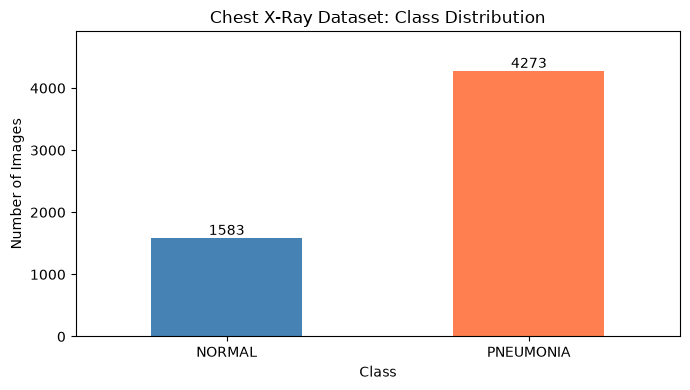

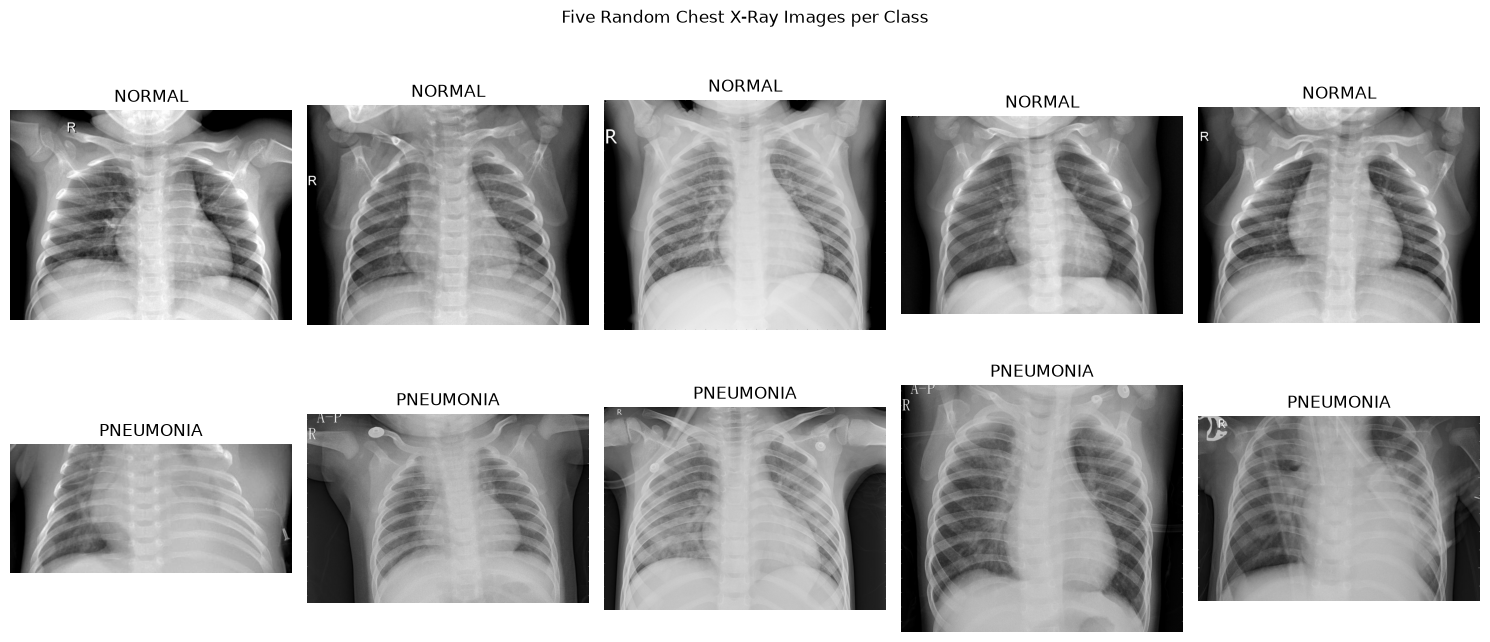

In [1]:
from pathlib import Path

import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Fetch and extract the dataset automatically
download_path = Path(
    kagglehub.dataset_download(
        "paultimothymooney/chest-xray-pneumonia"
    )
)

print("Downloaded dataset location:", download_path)

# Locate one complete dataset folder
classes = ["NORMAL", "PNEUMONIA"]
original_splits = ["train", "val", "test"]

candidate_folders = [download_path] + sorted(
    download_path.rglob("chest_xray"),
    key=lambda path: (len(path.parts), str(path))
)

dataset_root = next(
    (
        folder
        for folder in candidate_folders
        if all(
            (folder / split / label).is_dir()
            for split in original_splits
            for label in classes
        )
    ),
    None
)

if dataset_root is None:
    raise FileNotFoundError(
        "Could not locate the train, val and test class folders."
    )

print("Dataset folder used:", dataset_root)

# Create a table containing image paths and labels
records = []
valid_extensions = {".jpg", ".jpeg", ".png"}

for split in original_splits:
    for label in classes:
        class_folder = dataset_root / split / label

        for image_path in sorted(class_folder.iterdir()):
            if (
                image_path.is_file()
                and image_path.suffix.lower() in valid_extensions
                and not image_path.name.startswith(".")
            ):
                records.append({
                    "filepath": str(image_path),
                    "label": label,
                    "original_split": split
                })

image_df = pd.DataFrame(records)

if image_df.empty:
    raise ValueError("No image files were found.")

print("\nFirst five records:")
print(image_df.head().to_string(index=False))

print("\nTotal images:", len(image_df))

# Report counts in the supplied dataset folders
split_counts = pd.crosstab(
    image_df["original_split"],
    image_df["label"]
).reindex(
    index=original_splits,
    columns=classes,
    fill_value=0
)

print("\nImages in the original dataset splits:")
print(split_counts)

# Report overall class balance
class_counts = image_df["label"].value_counts().reindex(classes)

class_summary = pd.DataFrame({
    "Number of Images": class_counts,
    "Percentage": (class_counts / len(image_df) * 100).round(2)
})

print("\nOverall class distribution:")
print(class_summary)

ax = class_counts.plot(
    kind="bar",
    color=["steelblue", "coral"],
    figsize=(7, 4)
)

for position, count in enumerate(class_counts):
    ax.text(position, count, str(count), ha="center", va="bottom")

plt.title("Chest X-Ray Dataset: Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.ylim(0, class_counts.max() * 1.15)
plt.tight_layout()
plt.show()

# Display five random images from each class
fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for row, label in enumerate(classes):
    samples = image_df[
        image_df["label"] == label
    ].sample(n=5, random_state=42)

    for column, filepath in enumerate(samples["filepath"]):
        with Image.open(filepath) as image:
            axes[row, column].imshow(
                image.convert("L"),
                cmap="gray"
            )

        axes[row, column].set_title(label)
        axes[row, column].axis("off")

plt.suptitle("Five Random Chest X-Ray Images per Class")
plt.tight_layout()
plt.show()

Task 2: Data Preprocessing 

In [2]:
%pip install scikit-image==0.25.2 tqdm

   ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
   ------ --------------------------------- 2.1/12.8 MB 114.7 MB/s eta 0:00:01
   ------ --------------------------------- 2.1/12.8 MB 114.7 MB/s eta 0:00:01
   ------ --------------------------------- 2.1/12.8 MB 114.7 MB/s eta 0:00:01
   ------ --------------------------------- 2.1/12.8 MB 114.7 MB/s eta 0:00:01
   ---------------------- ----------------- 7.1/12.8 MB 6.9 MB/s eta 0:00:01
   ---------------------------------------- 12.8/12.8 MB 12.0 MB/s  0:00:01

   ---------------------------------------- 0/3 [tifffile]
   ---------------------------------------- 0/3 [tifffile]
   ---------------------------------------- 0/3 [tifffile]
   ------------- -------------------------- 1/3 [imageio]
   ------------- -------------------------- 1/3 [imageio]
   ------------- -------------------------- 1/3 [imageio]
   ------------- -------------------------- 1/3 [imageio]
   ------------- -------------------------- 1/3 [im


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Data split:
     Split  Images  Percentage  Normal  Pneumonia
  Training    4120       70.36    1114       3006
Validation     890       15.20     234        656
   Testing     846       14.45     235        611


Processing images:   0%|          | 0/5856 [00:00<?, ?it/s]


Feature extraction completed.
HOG features per image: 1764
LBP features per image: 10
GLCM features per image: 24
Combined features per image: 1798

CNN image shapes:
Training: (4120, 128, 128, 1)
Validation: (890, 128, 128, 1)
Testing: (846, 128, 128, 1)

Feature vector shapes:
Training: (4120, 1798)
Validation: (890, 1798)
Testing: (846, 1798)

Target shapes:
Training: (4120,)
Validation: (890,)
Testing: (846,)

CNN training pixel range:
0.0 to 1.0

Label mapping: {'NORMAL': 0, 'PNEUMONIA': 1}
Patient groups do not overlap between splits.


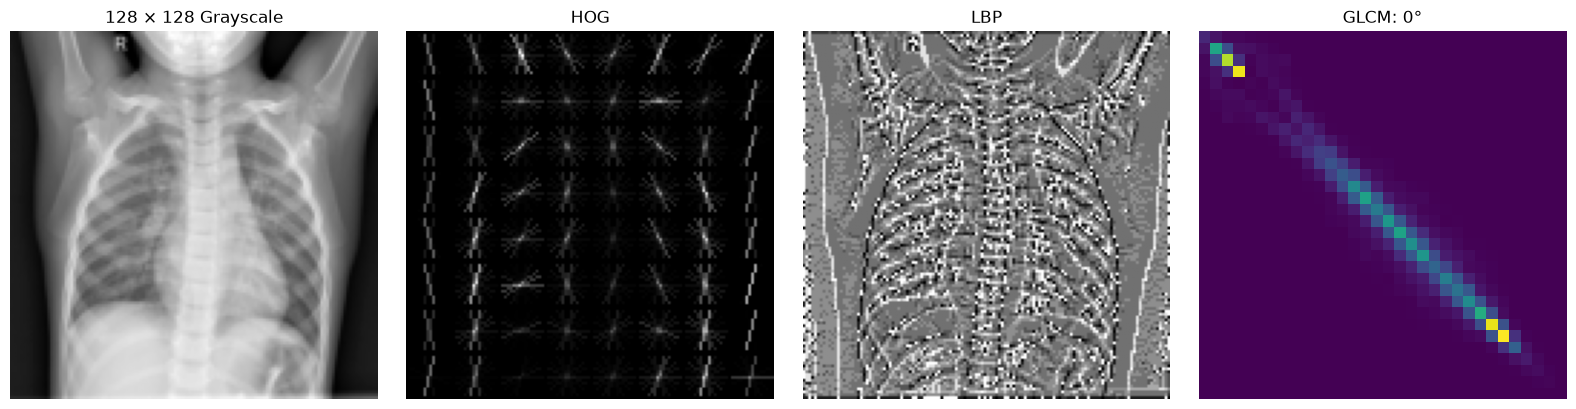

In [3]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm

from skimage.feature import (
    hog,
    local_binary_pattern,
    graycomatrix,
    graycoprops
)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


# 1. Prepare labels and patient groups
data_df = image_df.copy().reset_index(drop=True)

label_mapping = {"NORMAL": 0, "PNEUMONIA": 1}
data_df["target"] = data_df["label"].map(label_mapping)

if data_df["target"].isna().any():
    raise ValueError("Unexpected class labels found.")


def get_patient_group(filepath):
    name = Path(filepath).stem

    pneumonia_match = re.match(r"(person\d+)_", name, re.I)
    normal_match = re.match(r"((?:NORMAL2-)?IM-\d+)-", name, re.I)

    if pneumonia_match:
        return pneumonia_match.group(1).upper()

    if normal_match:
        return normal_match.group(1).upper()

    raise ValueError(f"Unrecognized patient filename: {name}")


data_df["patient_group"] = data_df["filepath"].apply(
    get_patient_group
)

label_counts = data_df.groupby("patient_group")["target"].nunique()

if (label_counts > 1).any():
    raise ValueError("A patient group contains conflicting labels.")


# 2. Split patient groups approximately 70 / 15 / 15
patient_df = data_df[
    ["patient_group", "target"]
].drop_duplicates()

train_patients, remaining_patients = train_test_split(
    patient_df,
    test_size=0.30,
    stratify=patient_df["target"],
    random_state=42
)

val_patients, test_patients = train_test_split(
    remaining_patients,
    test_size=0.50,
    stratify=remaining_patients["target"],
    random_state=42
)

train_idx = data_df.index[
    data_df["patient_group"].isin(train_patients["patient_group"])
].to_numpy()

val_idx = data_df.index[
    data_df["patient_group"].isin(val_patients["patient_group"])
].to_numpy()

test_idx = data_df.index[
    data_df["patient_group"].isin(test_patients["patient_group"])
].to_numpy()

train_groups = set(train_patients["patient_group"])
val_groups = set(val_patients["patient_group"])
test_groups = set(test_patients["patient_group"])

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

assert len(train_idx) + len(val_idx) + len(test_idx) == len(data_df)

split_summary = []

for split_name, indices in [
    ("Training", train_idx),
    ("Validation", val_idx),
    ("Testing", test_idx)
]:
    subset = data_df.loc[indices]

    split_summary.append({
        "Split": split_name,
        "Images": len(subset),
        "Percentage": round(100 * len(subset) / len(data_df), 2),
        "Normal": (subset["target"] == 0).sum(),
        "Pneumonia": (subset["target"] == 1).sum()
    })

print("Data split:")
print(pd.DataFrame(split_summary).to_string(index=False))


# 3. Define image preprocessing and feature extraction
IMAGE_SIZE = (128, 128)

glcm_properties = [
    "contrast",
    "dissimilarity",
    "homogeneity",
    "energy",
    "correlation",
    "ASM"
]


def load_image(filepath):
    with Image.open(filepath) as image:
        image = image.convert("L")
        image = image.resize(
            IMAGE_SIZE,
            Image.Resampling.BILINEAR
        )
        return np.array(image, dtype=np.uint8)


def extract_features(image):
    hog_features = hog(
        image,
        orientations=9,
        pixels_per_cell=(16, 16),
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
        feature_vector=True
    )

    lbp = local_binary_pattern(
        image,
        P=8,
        R=1,
        method="uniform"
    )

    lbp_histogram, _ = np.histogram(
        lbp,
        bins=np.arange(11),
        range=(0, 10)
    )

    lbp_features = lbp_histogram.astype(np.float32)
    lbp_features /= lbp_features.sum()

    # Reduce 256 intensity levels to 32 for efficient GLCM calculation
    quantized_image = image // 8

    glcm = graycomatrix(
        quantized_image,
        distances=[1],
        angles=[0, np.pi / 4, np.pi / 2, 3 * np.pi / 4],
        levels=32,
        symmetric=True,
        normed=True
    )

    glcm_features = np.concatenate([
        graycoprops(glcm, property_name).ravel()
        for property_name in glcm_properties
    ])

    return np.concatenate([
        hog_features,
        lbp_features,
        glcm_features
    ]).astype(np.float32)


# 4. Process every image and build feature vectors
number_of_images = len(data_df)

images_uint8 = np.empty(
    (number_of_images, 128, 128),
    dtype=np.uint8
)

feature_vectors = np.empty(
    (number_of_images, 1798),
    dtype=np.float32
)

for index, filepath in enumerate(
    tqdm(data_df["filepath"], desc="Processing images")
):
    image = load_image(filepath)

    images_uint8[index] = image
    feature_vectors[index] = extract_features(image)

labels = data_df["target"].to_numpy(dtype=np.int32)

assert np.isfinite(feature_vectors).all()

print("\nFeature extraction completed.")
print("HOG features per image: 1764")
print("LBP features per image: 10")
print("GLCM features per image: 24")
print("Combined features per image:", feature_vectors.shape[1])


# 5. Prepare normalized CNN inputs
def prepare_cnn_images(indices):
    return (
        images_uint8[indices, ..., np.newaxis].astype(np.float32)
        / 255.0
    )


X_train_cnn = prepare_cnn_images(train_idx)
X_val_cnn = prepare_cnn_images(val_idx)
X_test_cnn = prepare_cnn_images(test_idx)

y_train = labels[train_idx]
y_val = labels[val_idx]
y_test = labels[test_idx]


# 6. Prepare feature-based classifier inputs
X_train_features = feature_vectors[train_idx]
X_val_features = feature_vectors[val_idx]
X_test_features = feature_vectors[test_idx]

# Fit only on training data
feature_scaler = StandardScaler()

X_train_features_scaled = feature_scaler.fit_transform(
    X_train_features
)

X_val_features_scaled = feature_scaler.transform(
    X_val_features
)

X_test_features_scaled = feature_scaler.transform(
    X_test_features
)

# Preserve group identifiers for cross-validation in Task 3
groups_train = data_df.loc[
    train_idx, "patient_group"
].to_numpy()


# 7. Display final shapes
print("\nCNN image shapes:")
print("Training:", X_train_cnn.shape)
print("Validation:", X_val_cnn.shape)
print("Testing:", X_test_cnn.shape)

print("\nFeature vector shapes:")
print("Training:", X_train_features.shape)
print("Validation:", X_val_features.shape)
print("Testing:", X_test_features.shape)

print("\nTarget shapes:")
print("Training:", y_train.shape)
print("Validation:", y_val.shape)
print("Testing:", y_test.shape)

print("\nCNN training pixel range:")
print(X_train_cnn.min(), "to", X_train_cnn.max())

print("\nLabel mapping:", label_mapping)
print("Patient groups do not overlap between splits.")


# 8. Visualize preprocessing and extracted patterns
example = images_uint8[train_idx[0]]

_, hog_image = hog(
    example,
    orientations=9,
    pixels_per_cell=(16, 16),
    cells_per_block=(2, 2),
    block_norm="L2-Hys",
    visualize=True
)

lbp_image = local_binary_pattern(
    example,
    P=8,
    R=1,
    method="uniform"
)

example_glcm = graycomatrix(
    example // 8,
    distances=[1],
    angles=[0],
    levels=32,
    symmetric=True,
    normed=True
)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(example, cmap="gray")
axes[0].set_title("128 × 128 Grayscale")

axes[1].imshow(hog_image, cmap="gray")
axes[1].set_title("HOG")

axes[2].imshow(lbp_image, cmap="gray")
axes[2].set_title("LBP")

axes[3].imshow(example_glcm[:, :, 0, 0], cmap="viridis")
axes[3].set_title("GLCM: 0°")

for axis in axes:
    axis.axis("off")

plt.tight_layout()
plt.show()

Task 3: Model Training and Basic Evaluation 

TensorFlow version: 2.19.0
Available GPUs: []

Testing CNN configuration: {'filters': 16, 'learning_rate': 0.001}
Fold 1/3 completed | AUROC: 0.9857
Fold 2/3 completed | AUROC: 0.9891
Fold 3/3 completed | AUROC: 0.9869

Testing CNN configuration: {'filters': 16, 'learning_rate': 0.0003}
Fold 1/3 completed | AUROC: 0.9849
Fold 2/3 completed | AUROC: 0.9873
Fold 3/3 completed | AUROC: 0.9869

Testing CNN configuration: {'filters': 32, 'learning_rate': 0.001}
Fold 1/3 completed | AUROC: 0.9777
Fold 2/3 completed | AUROC: 0.9871
Fold 3/3 completed | AUROC: 0.9843

Testing CNN configuration: {'filters': 32, 'learning_rate': 0.0003}
Fold 1/3 completed | AUROC: 0.9856
Fold 2/3 completed | AUROC: 0.9868
Fold 3/3 completed | AUROC: 0.9862

CNN GRID SEARCH RESULTS
 filters  learning_rate  Mean CV AUROC  Std CV AUROC
      16         0.0010       0.987216      0.001429
      16         0.0003       0.986356      0.001043
      32         0.0003       0.986192      0.000512
      32         0.0010

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 16)   │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,048,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,216,005 (12.27 MB)

 Trainable params: 1,072,001 (4.09 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,144,004 (8.18 MB)

Fitting 3 folds for each of 3 candidates, totalling 9 fits

FEATURE CLASSIFIER GRID SEARCH RESULTS
                 params  mean_test_score  std_test_score
{'classifier__C': 0.01}         0.987413        0.000866
 {'classifier__C': 0.1}         0.983865        0.001409
 {'classifier__C': 1.0}         0.980885        0.001462

Selected parameters: {'classifier__C': 0.01}
Best CV AUROC: 0.9874

VALIDATION COMPARISON
                           Model  Validation AUROC
HOG+LBP+GLCM Logistic Regression          0.990007
                             CNN          0.989238

Model selected using validation AUROC:
HOG+LBP+GLCM Logistic Regression

CLASSIFICATION REPORT: CNN
              precision    recall  f1-score   support

      NORMAL       0.83      0.97      0.89       235
   PNEUMONIA       0.99      0.92      0.95       611

    accuracy                           0.94       846
   macro avg       0.91      0.95      0.92       846
weighted avg       0.94      0.94      0.94       846

C

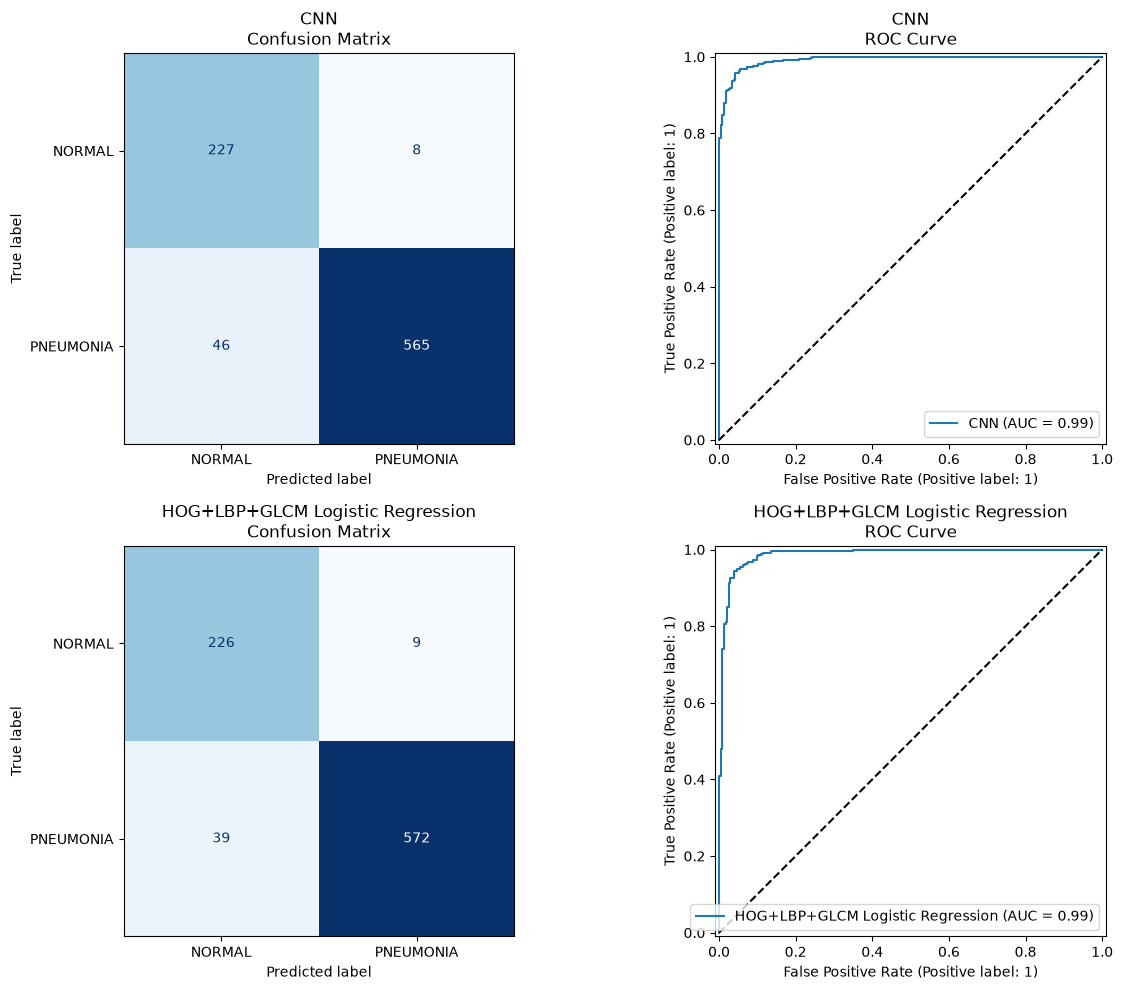

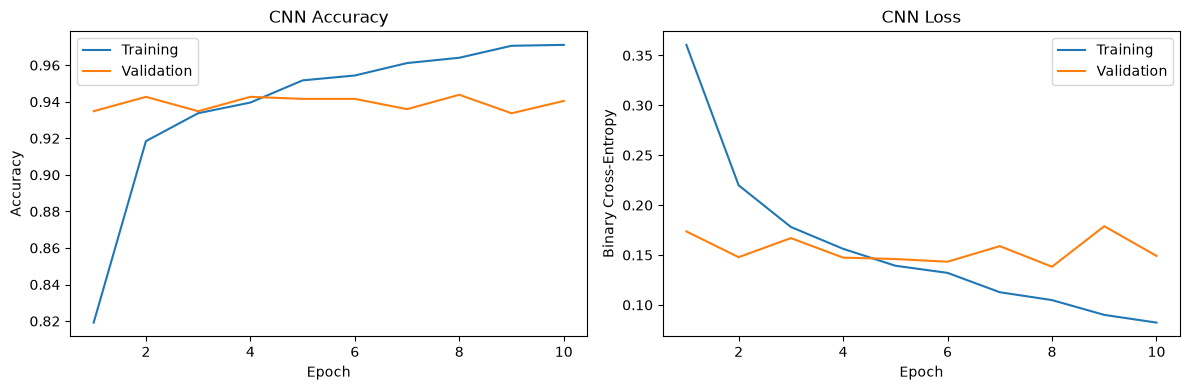

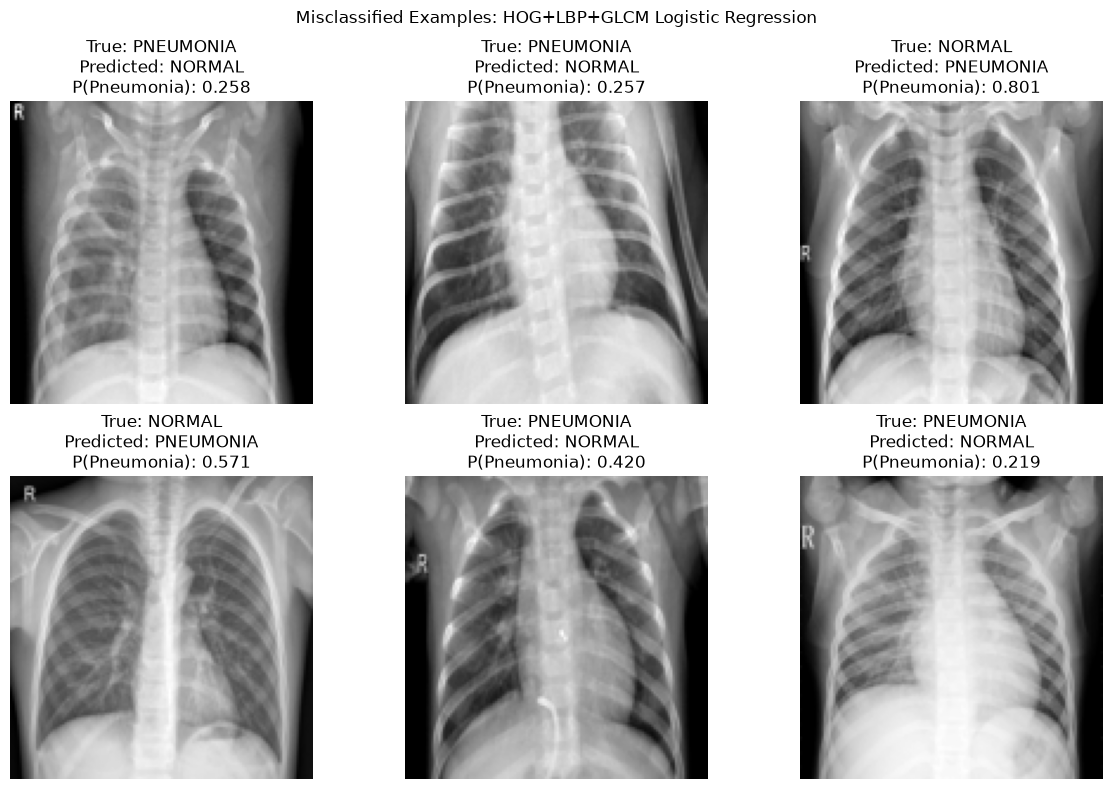

In [4]:
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras

from keras import Sequential
from keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)
from keras.optimizers import Adam

from sklearn.model_selection import (
    StratifiedGroupKFold,
    ParameterGrid,
    GridSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)


# 1. Basic settings
SEED = 42
EPOCHS = 10
BATCH_SIZE = 32

keras.utils.set_random_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

assert len(X_train_cnn) == len(X_train_features) == len(y_train)
assert len(groups_train) == len(y_train)

class_names = ["NORMAL", "PNEUMONIA"]


def get_class_weights(y):
    classes = np.unique(y)

    weights = compute_class_weight(
        class_weight="balanced",
        classes=classes,
        y=y
    )

    return {
        int(label): float(weight)
        for label, weight in zip(classes, weights)
    }


# 2. Create common cross-validation folds
cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED
)

cv_splits = list(
    cv.split(
        X_train_features,
        y_train,
        groups=groups_train
    )
)

for train_fold, validation_fold in cv_splits:
    assert set(groups_train[train_fold]).isdisjoint(
        groups_train[validation_fold]
    )

    assert len(np.unique(y_train[train_fold])) == 2
    assert len(np.unique(y_train[validation_fold])) == 2


# 3. Define the baseline CNN architecture
def build_cnn(filters=16, learning_rate=0.001):
    model = Sequential([
        Input(shape=(128, 128, 1)),

        Conv2D(filters, 3, activation="relu", padding="same"),
        MaxPooling2D(2),

        Conv2D(filters * 2, 3, activation="relu", padding="same"),
        MaxPooling2D(2),

        Conv2D(filters * 4, 3, activation="relu", padding="same"),
        MaxPooling2D(2),

        Flatten(),
        Dense(64, activation="relu"),
        Dropout(0.3),
        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


# 4. Tune CNN hyperparameters using grouped cross-validation
cnn_parameter_grid = {
    "filters": [16, 32],
    "learning_rate": [0.001, 0.0003]
}

cnn_search_results = []

for parameters in ParameterGrid(cnn_parameter_grid):
    fold_scores = []

    print("\nTesting CNN configuration:", parameters)

    for fold_number, (train_fold, validation_fold) in enumerate(
        cv_splits,
        start=1
    ):
        keras.backend.clear_session()
        keras.utils.set_random_seed(SEED + fold_number)

        fold_model = build_cnn(**parameters)

        fold_model.fit(
            X_train_cnn[train_fold],
            y_train[train_fold],
            epochs=EPOCHS,
            batch_size=BATCH_SIZE,
            class_weight=get_class_weights(y_train[train_fold]),
            verbose=0
        )

        fold_probabilities = fold_model.predict(
            X_train_cnn[validation_fold],
            batch_size=BATCH_SIZE,
            verbose=0
        ).ravel()

        fold_auc = roc_auc_score(
            y_train[validation_fold],
            fold_probabilities
        )

        fold_scores.append(fold_auc)

        print(
            f"Fold {fold_number}/3 completed "
            f"| AUROC: {fold_auc:.4f}",
            flush=True
        )

        del fold_model
        gc.collect()

    cnn_search_results.append({
        **parameters,
        "Mean CV AUROC": np.mean(fold_scores),
        "Std CV AUROC": np.std(fold_scores)
    })

cnn_results_df = pd.DataFrame(cnn_search_results).sort_values(
    "Mean CV AUROC",
    ascending=False
)

print("\nCNN GRID SEARCH RESULTS")
print(cnn_results_df.to_string(index=False))

best_row = cnn_results_df.iloc[0]

best_cnn_parameters = {
    "filters": int(best_row["filters"]),
    "learning_rate": float(best_row["learning_rate"])
}

print("\nSelected CNN parameters:", best_cnn_parameters)


# 5. Train the selected CNN on all training images
keras.backend.clear_session()
keras.utils.set_random_seed(SEED)

cnn_model = build_cnn(**best_cnn_parameters)

history = cnn_model.fit(
    X_train_cnn,
    y_train,
    validation_data=(X_val_cnn, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=get_class_weights(y_train),
    verbose=2
)

cnn_model.summary()


# 6. Tune a classifier using the handcrafted features
# Scaling is fitted separately within each CV training fold
feature_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    (
        "classifier",
        LogisticRegression(
            class_weight="balanced",
            solver="liblinear",
            max_iter=2000,
            random_state=SEED
        )
    )
])

feature_search = GridSearchCV(
    estimator=feature_pipeline,
    param_grid={
        "classifier__C": [0.01, 0.1, 1.0]
    },
    scoring="roc_auc",
    cv=cv_splits,
    n_jobs=1,
    refit=True,
    verbose=1,
    error_score="raise"
)

feature_search.fit(X_train_features, y_train)

feature_model = feature_search.best_estimator_

print("\nFEATURE CLASSIFIER GRID SEARCH RESULTS")
print(
    pd.DataFrame(feature_search.cv_results_)[
        ["params", "mean_test_score", "std_test_score"]
    ].to_string(index=False)
)

print("\nSelected parameters:", feature_search.best_params_)
print(f"Best CV AUROC: {feature_search.best_score_:.4f}")


# 7. Compare models on validation data before testing
validation_probabilities = {
    "CNN": cnn_model.predict(
        X_val_cnn,
        batch_size=BATCH_SIZE,
        verbose=0
    ).ravel(),

    "HOG+LBP+GLCM Logistic Regression":
        feature_model.predict_proba(X_val_features)[:, 1]
}

validation_results = []

for name, probabilities in validation_probabilities.items():
    validation_results.append({
        "Model": name,
        "Validation AUROC": roc_auc_score(y_val, probabilities)
    })

validation_table = pd.DataFrame(validation_results).sort_values(
    "Validation AUROC",
    ascending=False
)

selected_model_name = validation_table.iloc[0]["Model"]

print("\nVALIDATION COMPARISON")
print(validation_table.to_string(index=False))

print("\nModel selected using validation AUROC:")
print(selected_model_name)


# 8. Evaluate both models on the held-out test set
test_probabilities = {
    "CNN": cnn_model.predict(
        X_test_cnn,
        batch_size=BATCH_SIZE,
        verbose=0
    ).ravel(),

    "HOG+LBP+GLCM Logistic Regression":
        feature_model.predict_proba(X_test_features)[:, 1]
}

test_results = []
test_predictions = {}

for name, probabilities in test_probabilities.items():
    predictions = (probabilities >= 0.5).astype(np.int32)
    test_predictions[name] = predictions

    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "AUROC": roc_auc_score(y_test, probabilities)
    })

    print(f"\nCLASSIFICATION REPORT: {name}")
    print(
        classification_report(
            y_test,
            predictions,
            labels=[0, 1],
            target_names=class_names,
            zero_division=0
        )
    )

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    ).ravel()

    print(f"Correctly classified normal images: {tn}")
    print(f"Correctly classified pneumonia images: {tp}")
    print(f"Normal incorrectly predicted as pneumonia: {fp}")
    print(f"Pneumonia incorrectly predicted as normal: {fn}")

comparison_df = pd.DataFrame(test_results)

print("\nFINAL TEST COMPARISON")
print(comparison_df.round(4).to_string(index=False))

print("\nSelected model, based on validation AUROC:")
print(selected_model_name)


# 9. Plot confusion matrices and ROC curves
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

for row, (name, probabilities) in enumerate(
    test_probabilities.items()
):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        test_predictions[name],
        labels=[0, 1],
        display_labels=class_names,
        cmap="Blues",
        colorbar=False,
        ax=axes[row, 0]
    )

    axes[row, 0].set_title(f"{name}\nConfusion Matrix")

    RocCurveDisplay.from_predictions(
        y_test,
        probabilities,
        name=name,
        ax=axes[row, 1]
    )

    axes[row, 1].plot([0, 1], [0, 1], "k--")
    axes[row, 1].set_title(f"{name}\nROC Curve")

plt.tight_layout()
plt.show()


# 10. Plot CNN training and validation curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epoch_numbers = range(1, len(history.history["loss"]) + 1)

axes[0].plot(
    epoch_numbers, history.history["accuracy"], label="Training"
)
axes[0].plot(
    epoch_numbers, history.history["val_accuracy"], label="Validation"
)
axes[0].set_title("CNN Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(
    epoch_numbers, history.history["loss"], label="Training"
)
axes[1].plot(
    epoch_numbers, history.history["val_loss"], label="Validation"
)
axes[1].set_title("CNN Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Binary Cross-Entropy")
axes[1].legend()

plt.tight_layout()
plt.show()


# 11. Display misclassified test images from the selected model
selected_predictions = test_predictions[selected_model_name]
selected_probabilities = test_probabilities[selected_model_name]

wrong_indices = np.flatnonzero(selected_predictions != y_test)

if len(wrong_indices) > 0:
    rng = np.random.default_rng(SEED)

    examples = rng.choice(
        wrong_indices,
        size=min(6, len(wrong_indices)),
        replace=False
    )

    fig, axes = plt.subplots(2, 3, figsize=(12, 8))
    axes = axes.ravel()

    for axis in axes:
        axis.axis("off")

    for axis, index in zip(axes, examples):
        axis.imshow(X_test_cnn[index, :, :, 0], cmap="gray")

        axis.set_title(
            f"True: {class_names[y_test[index]]}\n"
            f"Predicted: {class_names[selected_predictions[index]]}\n"
            f"P(Pneumonia): {selected_probabilities[index]:.3f}"
        )

    plt.suptitle(f"Misclassified Examples: {selected_model_name}")
    plt.tight_layout()
    plt.show()

else:
    print("\nNo misclassified test images.")